# Car Price Prediction

Regression project using Linear Regression, Random Forest, and Gradient Boosting.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Load Dataset

In [2]:
df = pd.read_csv(r"D:\ML DATA\CarPrice.csv")
df.head()

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [3]:
df.tail()

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
200,201,-1,volvo 145e (sw),gas,std,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845.0
201,202,-1,volvo 144ea,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045.0
202,203,-1,volvo 244dl,gas,std,four,sedan,rwd,front,109.1,...,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485.0
203,204,-1,volvo 246,diesel,turbo,four,sedan,rwd,front,109.1,...,145,idi,3.01,3.40,23.0,106,4800,26,27,22470.0
204,205,-1,volvo 264gl,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,19,25,22625.0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    object 
 3   fueltype          205 non-null    object 
 4   aspiration        205 non-null    object 
 5   doornumber        205 non-null    object 
 6   carbody           205 non-null    object 
 7   drivewheel        205 non-null    object 
 8   enginelocation    205 non-null    object 
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    object 
 15  cylindernumber    205 non-null    object 
 16  enginesize        205 non-null    int64  
 1

In [5]:
df.isnull().sum()

car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64

## Convert Categorical Columns

In [6]:
df["fueltype"] = df["fueltype"].map({"gas": 0, "diesel": 1})

In [7]:
df["aspiration"] = df["aspiration"].map({"std": 0, "turbo": 1})

In [8]:
df["doornumber"] = df["doornumber"].map({"two": 2, "four": 4})

In [9]:
df["carbody"] = df["carbody"].map({"convertible": 0, "hatchback": 1, "sedan": 2, "wagon": 3, "hardtop": 4})

In [10]:
df["drivewheel"] = df["drivewheel"].map({"fwd": 0, "rwd": 1, "4wd": 2})

In [11]:
df["enginelocation"] = df["enginelocation"].map({"front": 0, "rear": 1})

In [12]:
df["enginetype"] = df["enginetype"].map({"dohc": 0, "ohcv": 1, "ohc": 2, "l": 3, "rotor": 4, "ohcf": 5, "dohcv": 6})

In [13]:
df["cylindernumber"] = df["cylindernumber"].map({"two": 2, "three": 3, "four": 4, "five": 5, "six": 6, "eight": 8, "twelve": 12})

In [14]:
df["fuelsystem"] = df["fuelsystem"].map({"mpfi": 0, "2bbl": 1, "idi": 2, "1bbl": 3, "spdi": 4, "4bbl": 5, "mfi": 6, "spfi": 7})

## Convert CarName

In [15]:
df["CarName"].nunique()

147

In [16]:
car_map = {name: i for i, name in enumerate(df["CarName"].unique())}
df["CarName"] = df["CarName"].map(car_map)

## Remove Unnecessary / Optional Columns

In [17]:
df = df.drop(["car_ID", "symboling", "normalized-losses", "num-of-doors", "engine-location", "bore", "stroke", "compression-ratio", "peak-rpm"], axis=1, errors="ignore")
df.head()

,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,carwidth,...,cylindernumber,enginesize,fuelsystem,boreratio,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,0,0,0,2,0,1,0,88.6,168.8,64.1,...,4,130,0,3.47,9.0,111,5000,21,27,13495.0
1,1,0,0,2,0,1,0,88.6,168.8,64.1,...,4,130,0,3.47,9.0,111,5000,21,27,16500.0
2,2,0,0,2,1,1,0,94.5,171.2,65.5,...,6,152,0,2.68,9.0,154,5000,19,26,16500.0
3,3,0,0,4,2,0,0,99.8,176.6,66.2,...,4,109,0,3.19,10.0,102,5500,24,30,13950.0
4,4,0,0,4,2,2,0,99.4,176.6,66.4,...,5,136,0,3.19,8.0,115,5500,18,22,17450.0


In [18]:
df.info()
df.duplicated().sum()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   CarName           205 non-null    int64  
 1   fueltype          205 non-null    int64  
 2   aspiration        205 non-null    int64  
 3   doornumber        205 non-null    int64  
 4   carbody           205 non-null    int64  
 5   drivewheel        205 non-null    int64  
 6   enginelocation    205 non-null    int64  
 7   wheelbase         205 non-null    float64
 8   carlength         205 non-null    float64
 9   carwidth          205 non-null    float64
 10  carheight         205 non-null    float64
 11  curbweight        205 non-null    int64  
 12  enginetype        205 non-null    int64  
 13  cylindernumber    205 non-null    int64  
 14  enginesize        205 non-null    int64  
 15  fuelsystem        205 non-null    int64  
 16  boreratio         205 non-null    float64
 1

,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,carwidth,...,cylindernumber,enginesize,fuelsystem,boreratio,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.00000,205.000000,205.000000,205.000000,205.000000,205.000000,...,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,76.448780,0.097561,0.180488,3.121951,1.80000,0.458537,0.014634,98.756585,174.049268,65.907805,...,4.380488,126.907317,0.990244,3.329756,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,41.346261,0.297446,0.385535,0.994966,0.83666,0.581148,0.120377,6.021776,12.337289,2.145204,...,1.080854,41.642693,1.306058,0.270844,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,0.000000,0.000000,0.000000,2.000000,0.00000,0.000000,0.000000,86.600000,141.100000,60.300000,...,2.000000,61.000000,0.000000,2.540000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,43.000000,0.000000,0.000000,2.000000,1.00000,0.000000,0.000000,94.500000,166.300000,64.100000,...,4.000000,97.000000,0.000000,3.150000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,79.000000,0.000000,0.000000,4.000000,2.00000,0.000000,0.000000,97.000000,173.200000,65.500000,...,4.000000,120.000000,1.000000,3.310000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,113.000000,0.000000,0.000000,4.000000,2.00000,1.000000,0.000000,102.400000,183.100000,66.900000,...,4.000000,141.000000,1.000000,3.580000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,146.000000,1.000000,1.000000,4.000000,4.00000,2.000000,1.000000,120.900000,208.100000,72.300000,...,12.000000,326.000000,7.000000,3.940000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000


## EDA

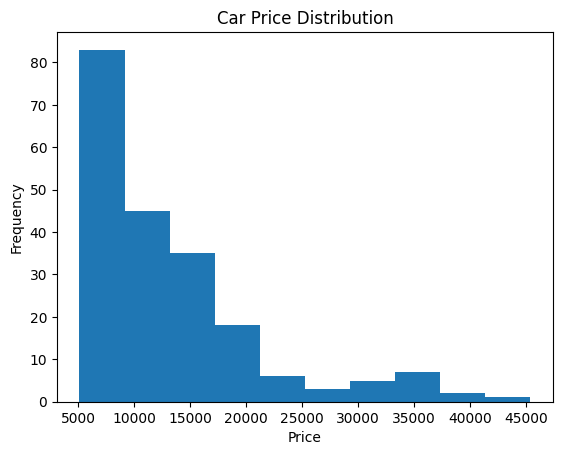

In [19]:
plt.hist(df["price"])
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.title("Car Price Distribution")
plt.show()

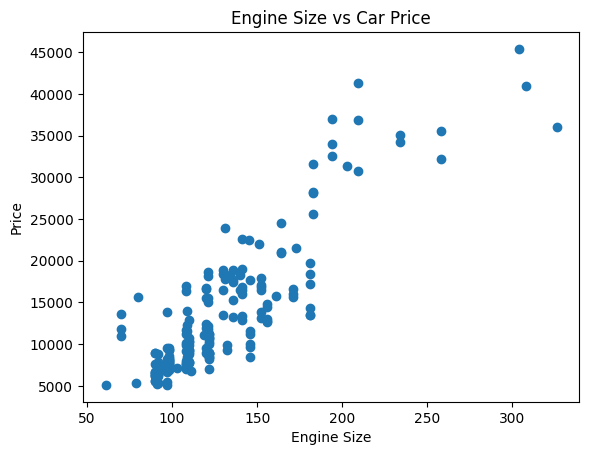

In [20]:
plt.scatter(df["enginesize"], df["price"])
plt.xlabel("Engine Size")
plt.ylabel("Price")
plt.title("Engine Size vs Car Price")
plt.show()

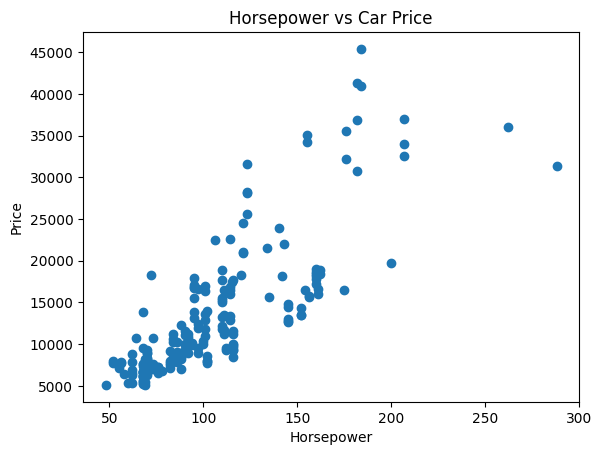

In [21]:
plt.scatter(df["horsepower"], df["price"])
plt.xlabel("Horsepower")
plt.ylabel("Price")
plt.title("Horsepower vs Car Price")
plt.show()

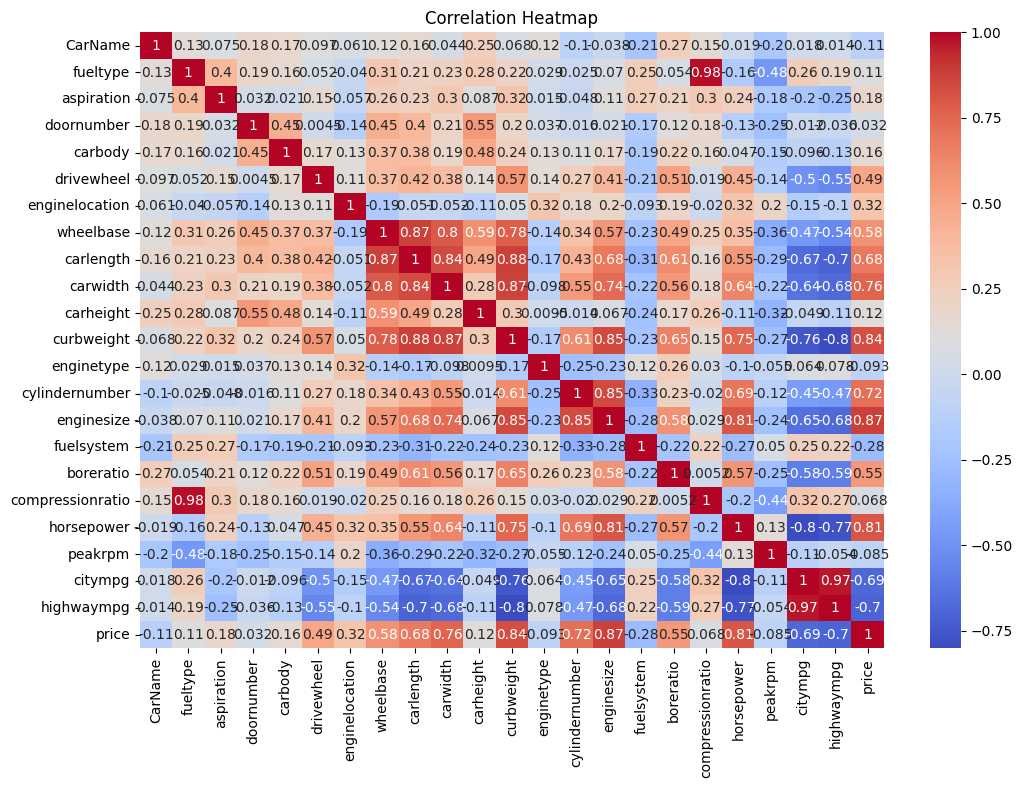

In [22]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [41]:
sorted(df["highwaympg"].unique())

[16,
 17,
 18,
 19,
 20,
 22,
 23,
 24,
 25,
 26,
 27,
 28,
 29,
 30,
 31,
 32,
 33,
 34,
 36,
 37,
 38,
 39,
 41,
 42,
 43,
 46,
 47,
 50,
 53,
 54]

## Features and Target

In [23]:
X = df.drop("price", axis=1)
y = df["price"]
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (205, 22)
y shape: (205,)


## Train-Test Split

In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (164, 22)
X_test: (41, 22)


## Evaluation Metrics

In [25]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate_model(y_test, y_pred):
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    print("MAE:", mae)
    print("MSE:", mse)
    print("RMSE:", rmse)
    print("R2 Score:", r2)

## Linear Regression

In [26]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)
evaluate_model(y_test, lr_pred)

MAE: 2325.026539636993
MSE: 11965329.504032455
RMSE: 3459.0937402782906
R2 Score: 0.8484327328313767


## Random Forest

In [27]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
evaluate_model(y_test, rf_pred)

MAE: 1333.798609756098
MSE: 3572775.1957668075
RMSE: 1890.1786147787218
R2 Score: 0.954742928521298


## Gradient Boosting

In [28]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42)
gb_model.fit(X_train, y_train)
gb_pred = gb_model.predict(X_test)
evaluate_model(y_test, gb_pred)

MAE: 1630.2357669889657
MSE: 5253898.839085923
RMSE: 2292.1384860182256
R2 Score: 0.933447792745508


## Model Comparison

In [29]:
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest", "Gradient Boosting"],
    "MAE": [mean_absolute_error(y_test, lr_pred), mean_absolute_error(y_test, rf_pred), mean_absolute_error(y_test, gb_pred)],
    "RMSE": [np.sqrt(mean_squared_error(y_test, lr_pred)), np.sqrt(mean_squared_error(y_test, rf_pred)), np.sqrt(mean_squared_error(y_test, gb_pred))],
    "R2 Score": [r2_score(y_test, lr_pred), r2_score(y_test, rf_pred), r2_score(y_test, gb_pred)]
})
comparison

,Model,MAE,RMSE,R2 Score
0,Linear Regression,2325.026540,3459.093740,0.848433
1,Random Forest,1333.798610,1890.178615,0.954743
2,Gradient Boosting,1630.235767,2292.138486,0.933448


## Random Forest Feature Importance

In [30]:
feature_importance = rf_model.feature_importances_

importance_df = pd.DataFrame({"Feature": X.columns, "Importance": feature_importance})
importance_df = importance_df.sort_values(by="Importance", ascending=False)
importance_df

,Feature,Importance
14,enginesize,5.558302e-01
11,curbweight,2.894487e-01
21,highwaympg,4.401378e-02
18,horsepower,2.937892e-02
0,CarName,2.110305e-02
9,carwidth,1.341901e-02
8,carlength,7.164390e-03
7,wheelbase,7.047626e-03
20,citympg,5.937390e-03
19,peakrpm,5.909939e-03


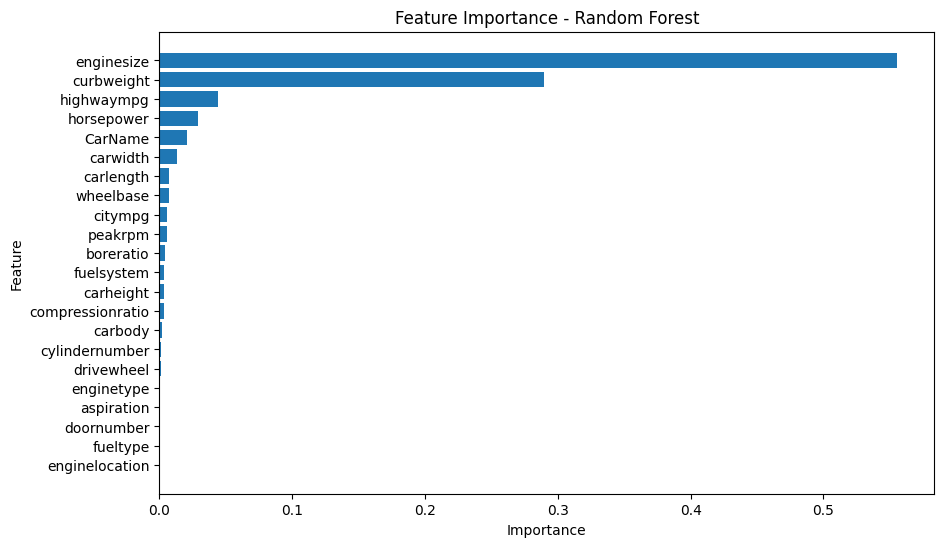

In [31]:
plt.figure(figsize=(10, 6))
plt.barh(importance_df["Feature"], importance_df["Importance"])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance - Random Forest")
plt.gca().invert_yaxis()
plt.show()

## Actual vs Predicted

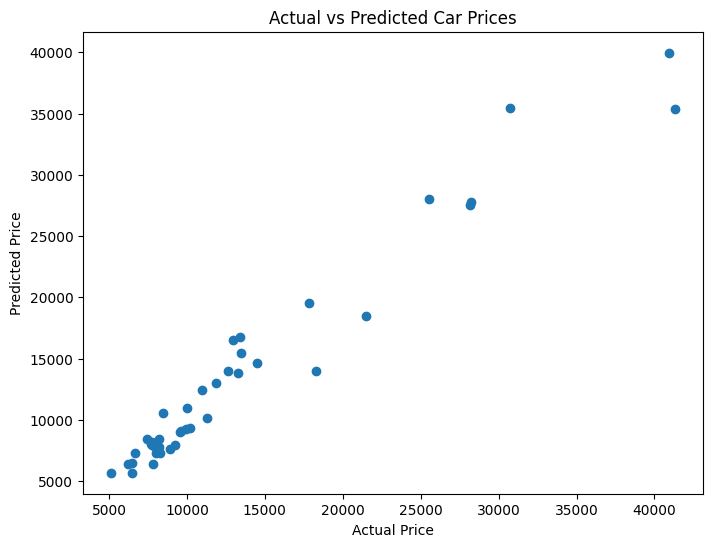

In [32]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, rf_pred)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Car Prices")
plt.show()

## Save Final Model

In [33]:
import joblib
joblib.dump(rf_model, "car_price_model.pkl")
print("Random Forest model saved successfully.")

Random Forest model saved successfully.


In [34]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV

rf = RandomForestRegressor(
    random_state=42
)

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": [1.0, "sqrt", "log2"]
}

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=RandomForestRegressor(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [None, 10, 20, 30],
                         'max_features': [1.0, 'sqrt', 'log2'],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [100, 200, 300]},
             scoring='r2')

In [36]:
rf=RandomForestRegressor(max_depth=10, max_features='sqrt', n_estimators=300,
                      random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
evaluate_model(y_test, rf_pred)


MAE: 1361.4628466597146
MSE: 4869896.605309221
RMSE: 2206.7842226437137
R2 Score: 0.9383120272942153


In [44]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   CarName           205 non-null    int64  
 1   fueltype          205 non-null    int64  
 2   aspiration        205 non-null    int64  
 3   doornumber        205 non-null    int64  
 4   carbody           205 non-null    int64  
 5   drivewheel        205 non-null    int64  
 6   enginelocation    205 non-null    int64  
 7   wheelbase         205 non-null    float64
 8   carlength         205 non-null    float64
 9   carwidth          205 non-null    float64
 10  carheight         205 non-null    float64
 11  curbweight        205 non-null    int64  
 12  enginetype        205 non-null    int64  
 13  cylindernumber    205 non-null    int64  
 14  enginesize        205 non-null    int64  
 15  fuelsystem        205 non-null    int64  
 16  boreratio         205 non-null    float64
 1

In [68]:
input_data = pd.DataFrame([[
    142,      # CarName
    0,        # fueltype
    0,        # aspiration
    4,        # doornumber
    2,        # carbody
    1,        # drivewheel
    0,        # enginelocation
    109.10,   # wheelbase
    188.80,   # carlength
    68.90,    # carwidth
    55.50,    # carheight
    3012,     # curbweight
    1,        # enginetype
    6,        # cylindernumber
    173,      # enginesize
    0,        # fuelsystem
    3.58,     # boreratio
    8.80,     # compressionratio
    134,      # horsepower
    5500,     # peakrpm
    18,       # citympg
    23        # highwaympg
]], columns=X.columns)


prediction = rf_model.predict(input_data)

print("Predicted Car Price:", prediction[0])

Predicted Car Price: 18477.26


In [67]:
df.loc[202]

CarName               142.00
fueltype                0.00
aspiration              0.00
doornumber              4.00
carbody                 2.00
drivewheel              1.00
enginelocation          0.00
wheelbase             109.10
carlength             188.80
carwidth               68.90
carheight              55.50
curbweight           3012.00
enginetype              1.00
cylindernumber          6.00
enginesize            173.00
fuelsystem              0.00
boreratio               3.58
compressionratio        8.80
horsepower            134.00
peakrpm              5500.00
citympg                18.00
highwaympg             23.00
price               21485.00
Name: 202, dtype: float64

In [69]:
import joblib

joblib.dump(rf, "car_price_model.pkl")
joblib.dump(car_map, "car_name_map.pkl")

print("Both files saved successfully!")

Both files saved successfully!
